# Model proportions strictly between zero and one

This example models continuous proportions strictly between zero and one. This beta model excludes exact zeros and ones; boundary observations need a model appropriate to their origin, rather than automatic clipping. Beta regression models its conditional mean through a logit link; it is different from modeling binary successes or binomial counts.

## Generate and fit the response

The split is fixed before fitting. Smoothing is selected on the training rows; the test outcomes are used only for final assessment.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from nampy.gam import GAM

rng=np.random.default_rng(108)
data=pd.DataFrame({"x":rng.uniform(0,1,700)})
grid=pd.DataFrame({"x":np.linspace(0,1,180)})
mu=expit(-.4+1.5*np.sin(2*np.pi*data.x))
precision=18
data["y"]=rng.beta(mu*precision,(1-mu)*precision)
train,test=train_test_split(data,test_size=.25,random_state=108)
model=GAM(formula="y ~ s(x,bs='cr',k=12)",family="betar",optimize_smoothing=True,smoothing_method="reml").fit(train)
true_grid=expit(-.4+1.5*np.sin(2*np.pi*grid.x))

## Inspect the mean and remaining variation

The mean curve describes expected responses rather than individual outcomes. The residual panel checks variation relative to the fitted family; held-out errors below use the response scale.

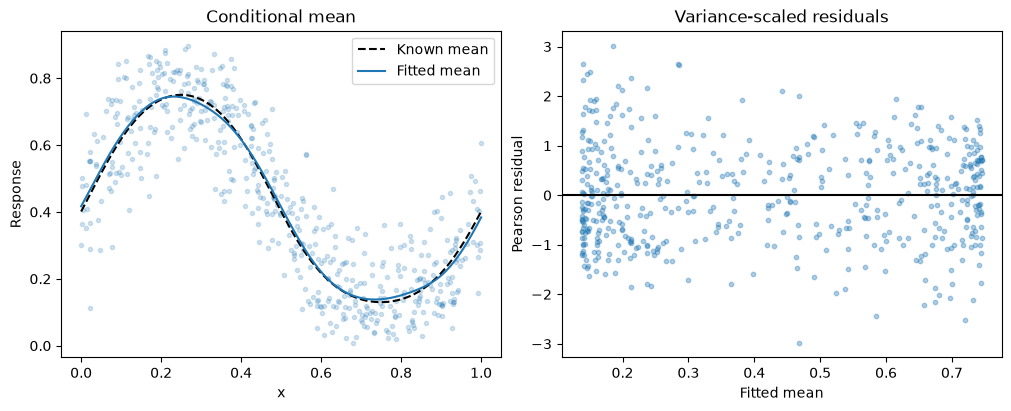

Test RMSE,Test MAE
0.097,0.077


In [2]:
figure,axes=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
axes[0].scatter(train.x,train.y,s=9,alpha=.2)
axes[0].plot(grid.x,true_grid,"k--",label="Known mean")
axes[0].plot(grid.x,model.predict(grid,type="response"),label="Fitted mean")
axes[0].set(xlabel="x",ylabel="Response",title="Conditional mean")
axes[0].legend()
axes[1].scatter(model.predict(train,type="response"),model.residuals(type="pearson"),s=10,alpha=.35)
axes[1].axhline(0,color="black")
axes[1].set(xlabel="Fitted mean",ylabel="Pearson residual",title="Variance-scaled residuals")
plt.show()
plt.close(figure)
prediction=model.predict(test,type="response")
pd.DataFrame({"Test RMSE":[mean_squared_error(test.y,prediction)**.5],"Test MAE":[np.mean(np.abs(test.y-prediction))]}).style.hide(axis="index").format("{:.3f}")

The fitted mean stays between zero and one and tracks the curved known proportion. Held-out RMSE is 0.097 and MAE is 0.077 on that proportion scale. The Pearson residuals assess variation relative to the fitted beta variance; bounded predictions alone do not establish a good fit.